# Bangla Sentence Classification (Function / Tense / Structure)
**Before running:** Runtime → Change runtime type → **T4 GPU** → Save.
Then run cells from top to bottom (Shift+Enter).

## 0. Setup

In [ ]:
# Install Bengali fonts to support rendering Bengali script in matplotlib plots and terminal output
!apt-get install -y fonts-beng

import matplotlib.pyplot as plt
import matplotlib as mpl

# Configure matplotlib to use the installed Lohit Bengali font for proper display of Bangla text
mpl.rcParams['font.family'] = 'Lohit Bengali'
mpl.rcParams['axes.unicode_minus'] = False
print("Bengali fonts installed and configured for plotting!")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-beng is already the newest version (2:1.3).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Bengali fonts installed and configured for plotting!


In [ ]:
!pip install -q transformers accelerate scikit-learn pandas seaborn joblib
!pip install -q git+https://github.com/csebuetnlp/normalizer


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import sys
# Force terminal/notebook environments to handle UTF-8 properly for Bengali text rendering
os.environ["PYTHONIOENCODING"] = "utf-8"
os.environ["LANG"] = "en_US.UTF-8"

import pandas as pd, numpy as np, torch, torch.nn as nn, json, random, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Configure pandas to display full unicode strings correctly
pd.set_option('display.max_colwidth', None)
pd.set_option('display.unicode.east_asian_width', True)

# Enable interactive Colab dataframe display to render HTML unicode text correctly
try:
    from google.colab import data_table
    data_table.enable_dataframe_formatter()
except ImportError:
    pass

FILE  = "/content/Bangla_Dataset_Lexical_Bias_Fixed_v4.xlsx"
SEED  = 42
# Load the Excel file present in the kernel
df = pd.read_excel(FILE)
TASKS = ["Function", "Tense", "Structure"]
print("Columns present in dataset:", list(df.columns))

# Force HTML table rendering of the dataframe to bypass terminal unicode bugs
from IPython.display import HTML
display(HTML(df.head(10).to_html(escape=False)))

Columns present in dataset: ['Sentence', 'Function', 'Tense', 'Structure']


,Sentence,Function,Tense,Structure
0,"সে কেন মিটিং মিস করবে, এবং কে বাকিদের জানাবে?",Interrogative,future,compound
1,"দারুণ, আগামীকালের দৃশ্যটি হবে অপূর্ব!",Exclamatory,future,simple
2,তারা পার্টিতে কখন পৌঁছেছিল যা সন্ধ্যা ৬টায় শুরু হয়েছিল,Interrogative,past,complex
3,"আমি একটি রিপোর্ট লিখব, এবং ক্লাস শুরু হওয়ার আগে জমা দেব।",Declarative,future,compound
4,আমরা স্কুলের পরে একসাথে পড়ি।,Declarative,present,simple
5,শহর কী আনন্দময় উৎসব উদযাপন করবে!,Exclamatory,future,simple
6,তখন তোমার বন্ধুর বয়স কত ছিল?,Interrogative,past,simple
7,"সূর্য পাহাড়ের পেছনে ডুবে যাচ্ছিল যখন আমরা আগুনের ধারে বসে ছিলাম, এবং আমরা অন্ধকার হওয়া পর্যন্ত থাকেছিলাম।",Declarative,past,complex
8,তারা কি বড় শহরে থাকে?,Interrogative,present,simple
9,"তারা ফরাসি সাবলীলভাবে বলবে, তাই তারা ফ্রান্সে তাদের ভ্রমণের সময় সহজে যোগাযোগ করবে, যা তারা শীঘ্রই পরিকল্পনা করবে।",Declarative,future,complex


In [ ]:
import html
from IPython.display import display, HTML

def display_bangla_df(dataframe, num_rows=10):
    """
    Explicitly renders a pandas DataFrame containing Bengali text into a clean HTML table
    with explicit UTF-8 styling and Bengali web-safe font fallback so that Bengali characters
    are beautifully readable and never render as question marks.
    """
    custom_css = """
    <style>
        .bangla-table {
            font-family: 'Lohit Bengali', 'Kalpurush', 'SolaimanLipi', sans-serif !important;
            border-collapse: collapse;
            width: 100%;
        }
        .bangla-table td, .bangla-table th {
            border: 1px solid #ddd;
            padding: 8px;
            text-align: left;
            font-size: 16px;
        }
        .bangla-table tr:nth-child(even){background-color: #f2f2f2;}
        .bangla-table th {
            padding-top: 12px;
            padding-bottom: 12px;
            background-color: #4CAF50;
            color: white;
        }
    </style>
    """

    # Generate manual HTML safely
    html_table = "<table class='bangla-table'><thead><tr>"
    for col in dataframe.columns:
        html_table += f"<th>{html.escape(str(col))}</th>"
    html_table += "</tr></thead><tbody>"

    for _, row in dataframe.head(num_rows).iterrows():
        html_table += "<tr>"
        for col in dataframe.columns:
            val = str(row[col])
            html_table += f"<td>{html.escape(val)}</td>"
        html_table += "</tr>"
    html_table += "</tbody></table>"

    display(HTML(custom_css + html_table))

# Let's verify the actual data loaded in the DataFrame with our explicit HTML renderer
print("Displaying the first 10 rows of the dataset using explicit HTML-UTF8 rendering:")
display_bangla_df(df, 10)

Displaying the first 10 rows of the dataset using explicit HTML-UTF8 rendering:


Sentence,Function,Tense,Structure
"সে কেন মিটিং মিস করবে, এবং কে বাকিদের জানাবে?",Interrogative,future,compound
"দারুণ, আগামীকালের দৃশ্যটি হবে অপূর্ব!",Exclamatory,future,simple
তারা পার্টিতে কখন পৌঁছেছিল যা সন্ধ্যা ৬টায় শুরু হয়েছিল,Interrogative,past,complex
"আমি একটি রিপোর্ট লিখব, এবং ক্লাস শুরু হওয়ার আগে জমা দেব।",Declarative,future,compound
আমরা স্কুলের পরে একসাথে পড়ি।,Declarative,present,simple
শহর কী আনন্দময় উৎসব উদযাপন করবে!,Exclamatory,future,simple
তখন তোমার বন্ধুর বয়স কত ছিল?,Interrogative,past,simple
"সূর্য পাহাড়ের পেছনে ডুবে যাচ্ছিল যখন আমরা আগুনের ধারে বসে ছিলাম, এবং আমরা অন্ধকার হওয়া পর্যন্ত থাকেছিলাম।",Declarative,past,complex
তারা কি বড় শহরে থাকে?,Interrogative,present,simple
"তারা ফরাসি সাবলীলভাবে বলবে, তাই তারা ফ্রান্সে তাদের ভ্রমণের সময় সহজে যোগাযোগ করবে, যা তারা শীঘ্রই পরিকল্পনা করবে।",Declarative,future,complex


## PART 1: Random Forest (CPU, ~2 min)

=== Function ===
               precision    recall  f1-score   support

  Declarative      0.990     0.980     0.985       100
  Exclamatory      0.970     0.980     0.975       100
   Imperative      0.980     1.000     0.990       100
Interrogative      1.000     0.980     0.990       100

     accuracy                          0.985       400
    macro avg      0.985     0.985     0.985       400
 weighted avg      0.985     0.985     0.985       400



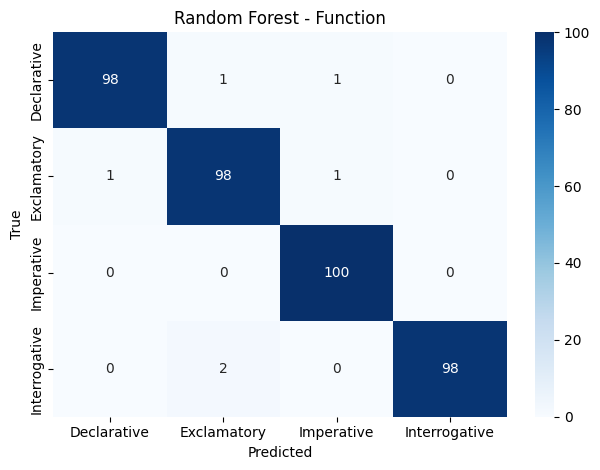

=== Tense ===
              precision    recall  f1-score   support

      future      1.000     0.894     0.944       132
        past      0.980     0.858     0.915       113
     present      0.836     0.987     0.905       155

    accuracy                          0.920       400
   macro avg      0.939     0.913     0.921       400
weighted avg      0.931     0.920     0.921       400



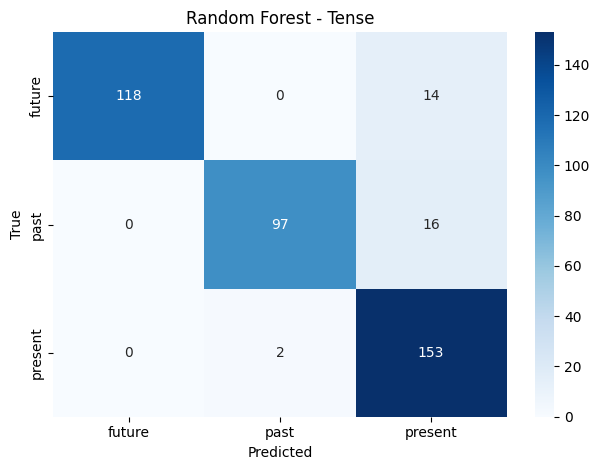

=== Structure ===
              precision    recall  f1-score   support

     complex      0.992     0.898     0.943       147
    compound      0.908     0.985     0.945       131
      simple      0.976     1.000     0.988       122

    accuracy                          0.958       400
   macro avg      0.959     0.961     0.959       400
weighted avg      0.960     0.958     0.957       400



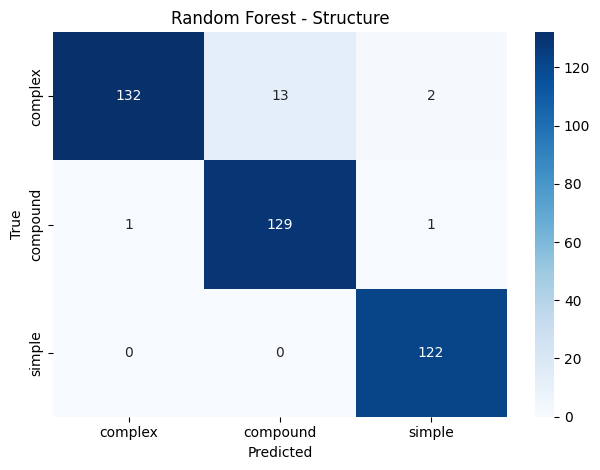

           test_acc  test_f1  cv_acc   cv_f1
Function     0.9850   0.9850  0.9785  0.9785
Tense        0.9200   0.9215  0.9420  0.9418
Structure    0.9575   0.9586  0.9615  0.9618


In [ ]:
def make_pipe():
    feats = FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1,2), sublinear_tf=True,
                                 token_pattern=r"[^\s,।?!;:]+")),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2,5), sublinear_tf=True))])
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
    return Pipeline([("feat", feats), ("rf", rf)])

# Strip whitespaces from column names to prevent KeyErrors
df.columns = df.columns.str.strip()

rf_summary = {}
for task in TASKS:
    X, y = df["Sentence"], df[task]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    model = make_pipe().fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f"=== {task} ===")
    print(classification_report(yte, pred, digits=3))
    cvp = cross_val_predict(make_pipe(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    rf_summary[task] = dict(test_acc=accuracy_score(yte, pred), test_f1=f1_score(yte, pred, average="macro"),
                            cv_acc=accuracy_score(y, cvp), cv_f1=f1_score(y, cvp, average="macro"))
    labels = sorted(y.unique())
    sns.heatmap(confusion_matrix(yte, pred, labels=labels), annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"Random Forest - {task}"); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.tight_layout(); plt.savefig(f"cm_rf_{task}.png", dpi=150); plt.show()
    joblib.dump(model, f"rf_{task}.joblib")
print(pd.DataFrame(rf_summary).T.round(4))

## PART 2: BanglaBERT (needs GPU, ~5-10 min)

In [ ]:
print("GPU available:", torch.cuda.is_available())
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

MODEL_NAME = "csebuetnlp/banglabert"
MAX_LEN, BATCH, EPOCHS, LR = 64, 16, 8, 3e-5
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    from normalizer import normalize
    df["text"] = df["Sentence"].apply(normalize)
except Exception:
    df["text"] = df["Sentence"]

label_maps = {t: {l:i for i,l in enumerate(sorted(df[t].unique()))} for t in TASKS}
inv_maps   = {t: {i:l for l,i in m.items()} for t,m in label_maps.items()}
for t in TASKS: df[t+"_id"] = df[t].map(label_maps[t])

strat = df["Function"] + "_" + df["Structure"]
train_df, tmp = train_test_split(df, test_size=0.2, stratify=strat, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=(tmp["Function"]+"_"+tmp["Structure"]), random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
class DS(Dataset):
    def __init__(self, d): self.d = d.reset_index(drop=True)
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        enc = tok(r["text"], truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
        item = {k: v.squeeze(0) for k, v in enc.items() if k != "token_type_ids"}
        for t in TASKS: item[t] = torch.tensor(r[t+"_id"])
        return item
tr_dl = DataLoader(DS(train_df), batch_size=BATCH, shuffle=True)
va_dl = DataLoader(DS(val_df), batch_size=BATCH*2)
te_dl = DataLoader(DS(test_df), batch_size=BATCH*2)

class MultiTask(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = AutoModel.from_pretrained(MODEL_NAME)
        h = self.enc.config.hidden_size
        self.drop = nn.Dropout(0.2)
        # Using dense layer projection before classification to resolve complex functions
        self.pre_classifiers = nn.ModuleDict({
            t: nn.Sequential(
                nn.Linear(h, h),
                nn.Tanh(),
                nn.Dropout(0.2)
            ) for t in TASKS
        })
        self.heads = nn.ModuleDict({t: nn.Linear(h, len(label_maps[t])) for t in TASKS})
    def forward(self, input_ids, attention_mask):
        out = self.enc(input_ids=input_ids, attention_mask=attention_mask)
        # Use CLS token representation for robust sentence-level classification
        cls_repr = out.last_hidden_state[:, 0, :]
        pooled = self.drop(cls_repr)

        logits = {}
        for t in TASKS:
            feat = self.pre_classifiers[t](pooled)
            logits[t] = self.heads[t](feat)
        return logits

model = MultiTask().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps = len(tr_dl)*EPOCHS
sched = get_linear_schedule_with_warmup(opt, int(0.1*steps), steps)
ce = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(dl):
    model.eval(); P={t:[] for t in TASKS}; Y={t:[] for t in TASKS}
    for b in dl:
        out = model(b["input_ids"].to(device), b["attention_mask"].to(device))
        for t in TASKS:
            P[t] += out[t].argmax(-1).cpu().tolist(); Y[t] += b[t].tolist()
    return P, Y

GPU available: True
1600 200 200


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
best, history = -1, []
for ep in range(1, EPOCHS+1):
    model.train(); tot = 0
    for b in tr_dl:
        out = model(b["input_ids"].to(device), b["attention_mask"].to(device))
        loss = sum(ce(out[t], b[t].to(device)) for t in TASKS)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        tot += loss.item()
    P, Y = evaluate(va_dl)
    f1s = {t: f1_score(Y[t], P[t], average="macro") for t in TASKS}
    avg = np.mean(list(f1s.values()))
    history.append(dict(epoch=ep, loss=tot/len(tr_dl), val_avg_f1=avg, **f1s))
    print(f"ep{ep} loss={tot/len(tr_dl):.4f} val_avgF1={avg:.4f} " + " ".join(f"{t}={f1s[t]:.3f}" for t in TASKS))
    if avg > best:
        best = avg
        torch.save(model.state_dict(), "best_multitask.pt")
pd.DataFrame(history).to_csv("bert_training_history.csv", index=False)

ep1 loss=2.9215 val_avgF1=0.9356 Function=1.000 Tense=0.950 Structure=0.857
ep2 loss=0.7078 val_avgF1=0.9871 Function=1.000 Tense=0.986 Structure=0.976
ep3 loss=0.1596 val_avgF1=0.9984 Function=1.000 Tense=1.000 Structure=0.995
ep4 loss=0.0474 val_avgF1=0.9935 Function=0.995 Tense=0.986 Structure=1.000
ep5 loss=0.0196 val_avgF1=0.9951 Function=1.000 Tense=0.995 Structure=0.990
ep6 loss=0.0134 val_avgF1=0.9983 Function=0.995 Tense=1.000 Structure=1.000
ep7 loss=0.0100 val_avgF1=1.0000 Function=1.000 Tense=1.000 Structure=1.000
ep8 loss=0.0089 val_avgF1=0.9983 Function=0.995 Tense=1.000 Structure=1.000



=== TEST: Function ===
               precision    recall  f1-score   support

  Declarative      1.000     1.000     1.000        51
  Exclamatory      1.000     1.000     1.000        50
   Imperative      1.000     1.000     1.000        50
Interrogative      1.000     1.000     1.000        49

     accuracy                          1.000       200
    macro avg      1.000     1.000     1.000       200
 weighted avg      1.000     1.000     1.000       200



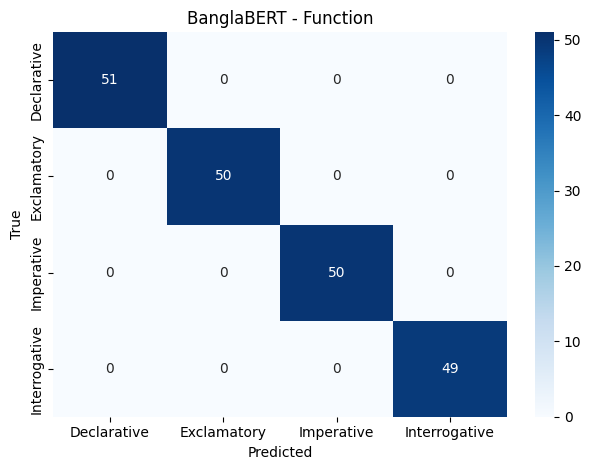


=== TEST: Tense ===
              precision    recall  f1-score   support

      future      1.000     1.000     1.000        65
        past      0.980     1.000     0.990        50
     present      1.000     0.988     0.994        85

    accuracy                          0.995       200
   macro avg      0.993     0.996     0.995       200
weighted avg      0.995     0.995     0.995       200



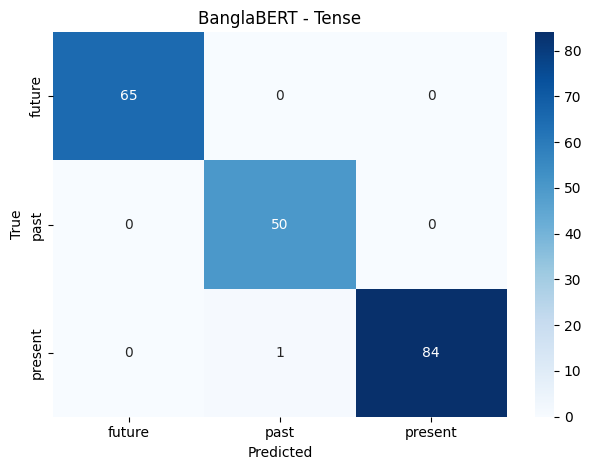


=== TEST: Structure ===
              precision    recall  f1-score   support

     complex      0.986     0.973     0.979        73
    compound      0.970     0.985     0.977        66
      simple      1.000     1.000     1.000        61

    accuracy                          0.985       200
   macro avg      0.985     0.986     0.986       200
weighted avg      0.985     0.985     0.985       200



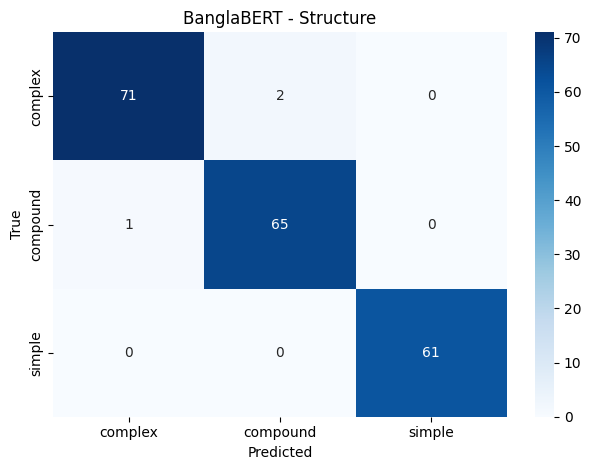

             acc  macro_f1
Function   1.000    1.0000
Tense      0.995    0.9947
Structure  0.985    0.9856


In [ ]:
model.load_state_dict(torch.load("best_multitask.pt"))
P, Y = evaluate(te_dl)
final = {}
for t in TASKS:
    names = [inv_maps[t][i] for i in range(len(inv_maps[t]))]
    print(f"\n=== TEST: {t} ===")
    print(classification_report(Y[t], P[t], target_names=names, digits=3))
    final[t] = dict(acc=accuracy_score(Y[t], P[t]), macro_f1=f1_score(Y[t], P[t], average="macro"))
    sns.heatmap(confusion_matrix(Y[t], P[t]), annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names)
    plt.title(f"BanglaBERT - {t}"); plt.ylabel("True"); plt.xlabel("Predicted"); plt.tight_layout()
    plt.savefig(f"cm_bert_{t}.png", dpi=150); plt.show()
json.dump(final, open("bert_test_results.json","w"), indent=2)
print(pd.DataFrame(final).T.round(4))

## Predict a new sentence

In [ ]:
@torch.no_grad()
def predict(sentence):
    model.eval()
    enc = tok(sentence, truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt").to(device)
    out = model(enc["input_ids"], enc["attention_mask"])
    return {t: inv_maps[t][out[t].argmax(-1).item()] for t in TASKS}
print(predict("(আমাদের রাষ্ট্রপতি দীর্ঘজীবী হোন।"))

{'Function': 'Imperative', 'Tense': 'present', 'Structure': 'simple'}


## Download results

In [ ]:
from google.colab import files
for f in ["bert_test_results.json","bert_training_history.csv","cm_bert_Function.png","cm_bert_Tense.png",
          "cm_bert_Structure.png","cm_rf_Function.png","cm_rf_Tense.png","cm_rf_Structure.png","best_multitask.pt"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (8 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>